# Map for 2026 AGU poster

In [84]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import cartopy.crs as ccrs
import cartopy.io.img_tiles as cimgt
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter

import cmcrameri.cm as cmc

from matplotlib import rc
rc("pdf", fonttype=42)

from geoscripts import maps
from geoscripts.dz import dz

In [85]:
sattelite = cimgt.GoogleTiles(
    url='https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}'
    )

hillshade = cimgt.GoogleTiles(
    url='https://server.arcgisonline.com/ArcGIS/rest/services/Elevation/World_Hillshade/MapServer/tile/{z}/{y}/{x}'
    )


tect_map = gpd.read_file('../maps/morocco_tectonic_map.gpkg',layer='polygons_colored')

smps = dz.load_all('../dz/')

In [86]:
# Detrital zircon samples and provenance groups (from analysis_dz.ipynb)
smps_ptr = [smp for smp in smps if smp.reported_age=='P-Tr' 
            and smp.source not in ['Foster-Baril','VanTongeren']
            and smp.latlon[1]>-20
            and smp.bestage.count()>=100]

spans = [(200,300),(300,500),(500,750),(900,1400),(1600,2500),(2500,3500)]
colors = ['#215f60', '#faccfa', '#828231', '#011959', '#391400', '#f19c6b']

for smp in smps_ptr:
    smp.meseta = ((smp.bestage>=spans[0][0])&(smp.bestage<spans[0][1])).sum()/smp.bestage.count()
    smp.reguibat = ((smp.bestage>=spans[-1][0])&(smp.bestage<spans[-1][1])).sum()/smp.bestage.count()
    if smp.meseta>=0.03:
        smp.color = colors[0]
    elif smp.reguibat>=0.15:
        smp.color = colors[5]
    else:
        smp.color = 'grey'

mr24_dict = {'MR24-006':'RH1','MR24-008':'JB2','MR24-009':'JB1','MR24-017':'JB3',
             'MR24-020':'MHA1','MR24-023':'MHA2'}

In [87]:
# Igneous samples (from analysis_igneous.ipynb)
smps_ig = [smp for smp in smps if smp.source=='VanTongeren' and smp.mda>200]

data = pd.read_csv('../published_data/Atlas_C-Tr_Ig_GchronCompilation_060126.csv',index_col=0)
data_ig = data[data['System']=='U-Pb'].copy()
data_ig[['Longitude (DD)', 'Latitude (DD)']] = data_ig[['Longitude (DD)', 'Latitude (DD)']].apply(pd.to_numeric, errors='coerce')

for smp in smps_ig:
    data_ig.loc[smp.name,['Latitude (DD)', 'Longitude (DD)']] = smp.latlon
    data_ig.loc[smp.name,'Age (Ma)'] = smp.mda

data_ig['New'] = data_ig['Source'].isna()

new_names_dict = {'MR24-012':'JBD2', 'MR24-013':'JBD3', 'MR24-015':'JBD4',
                  'MR24-016':'JBD5'}

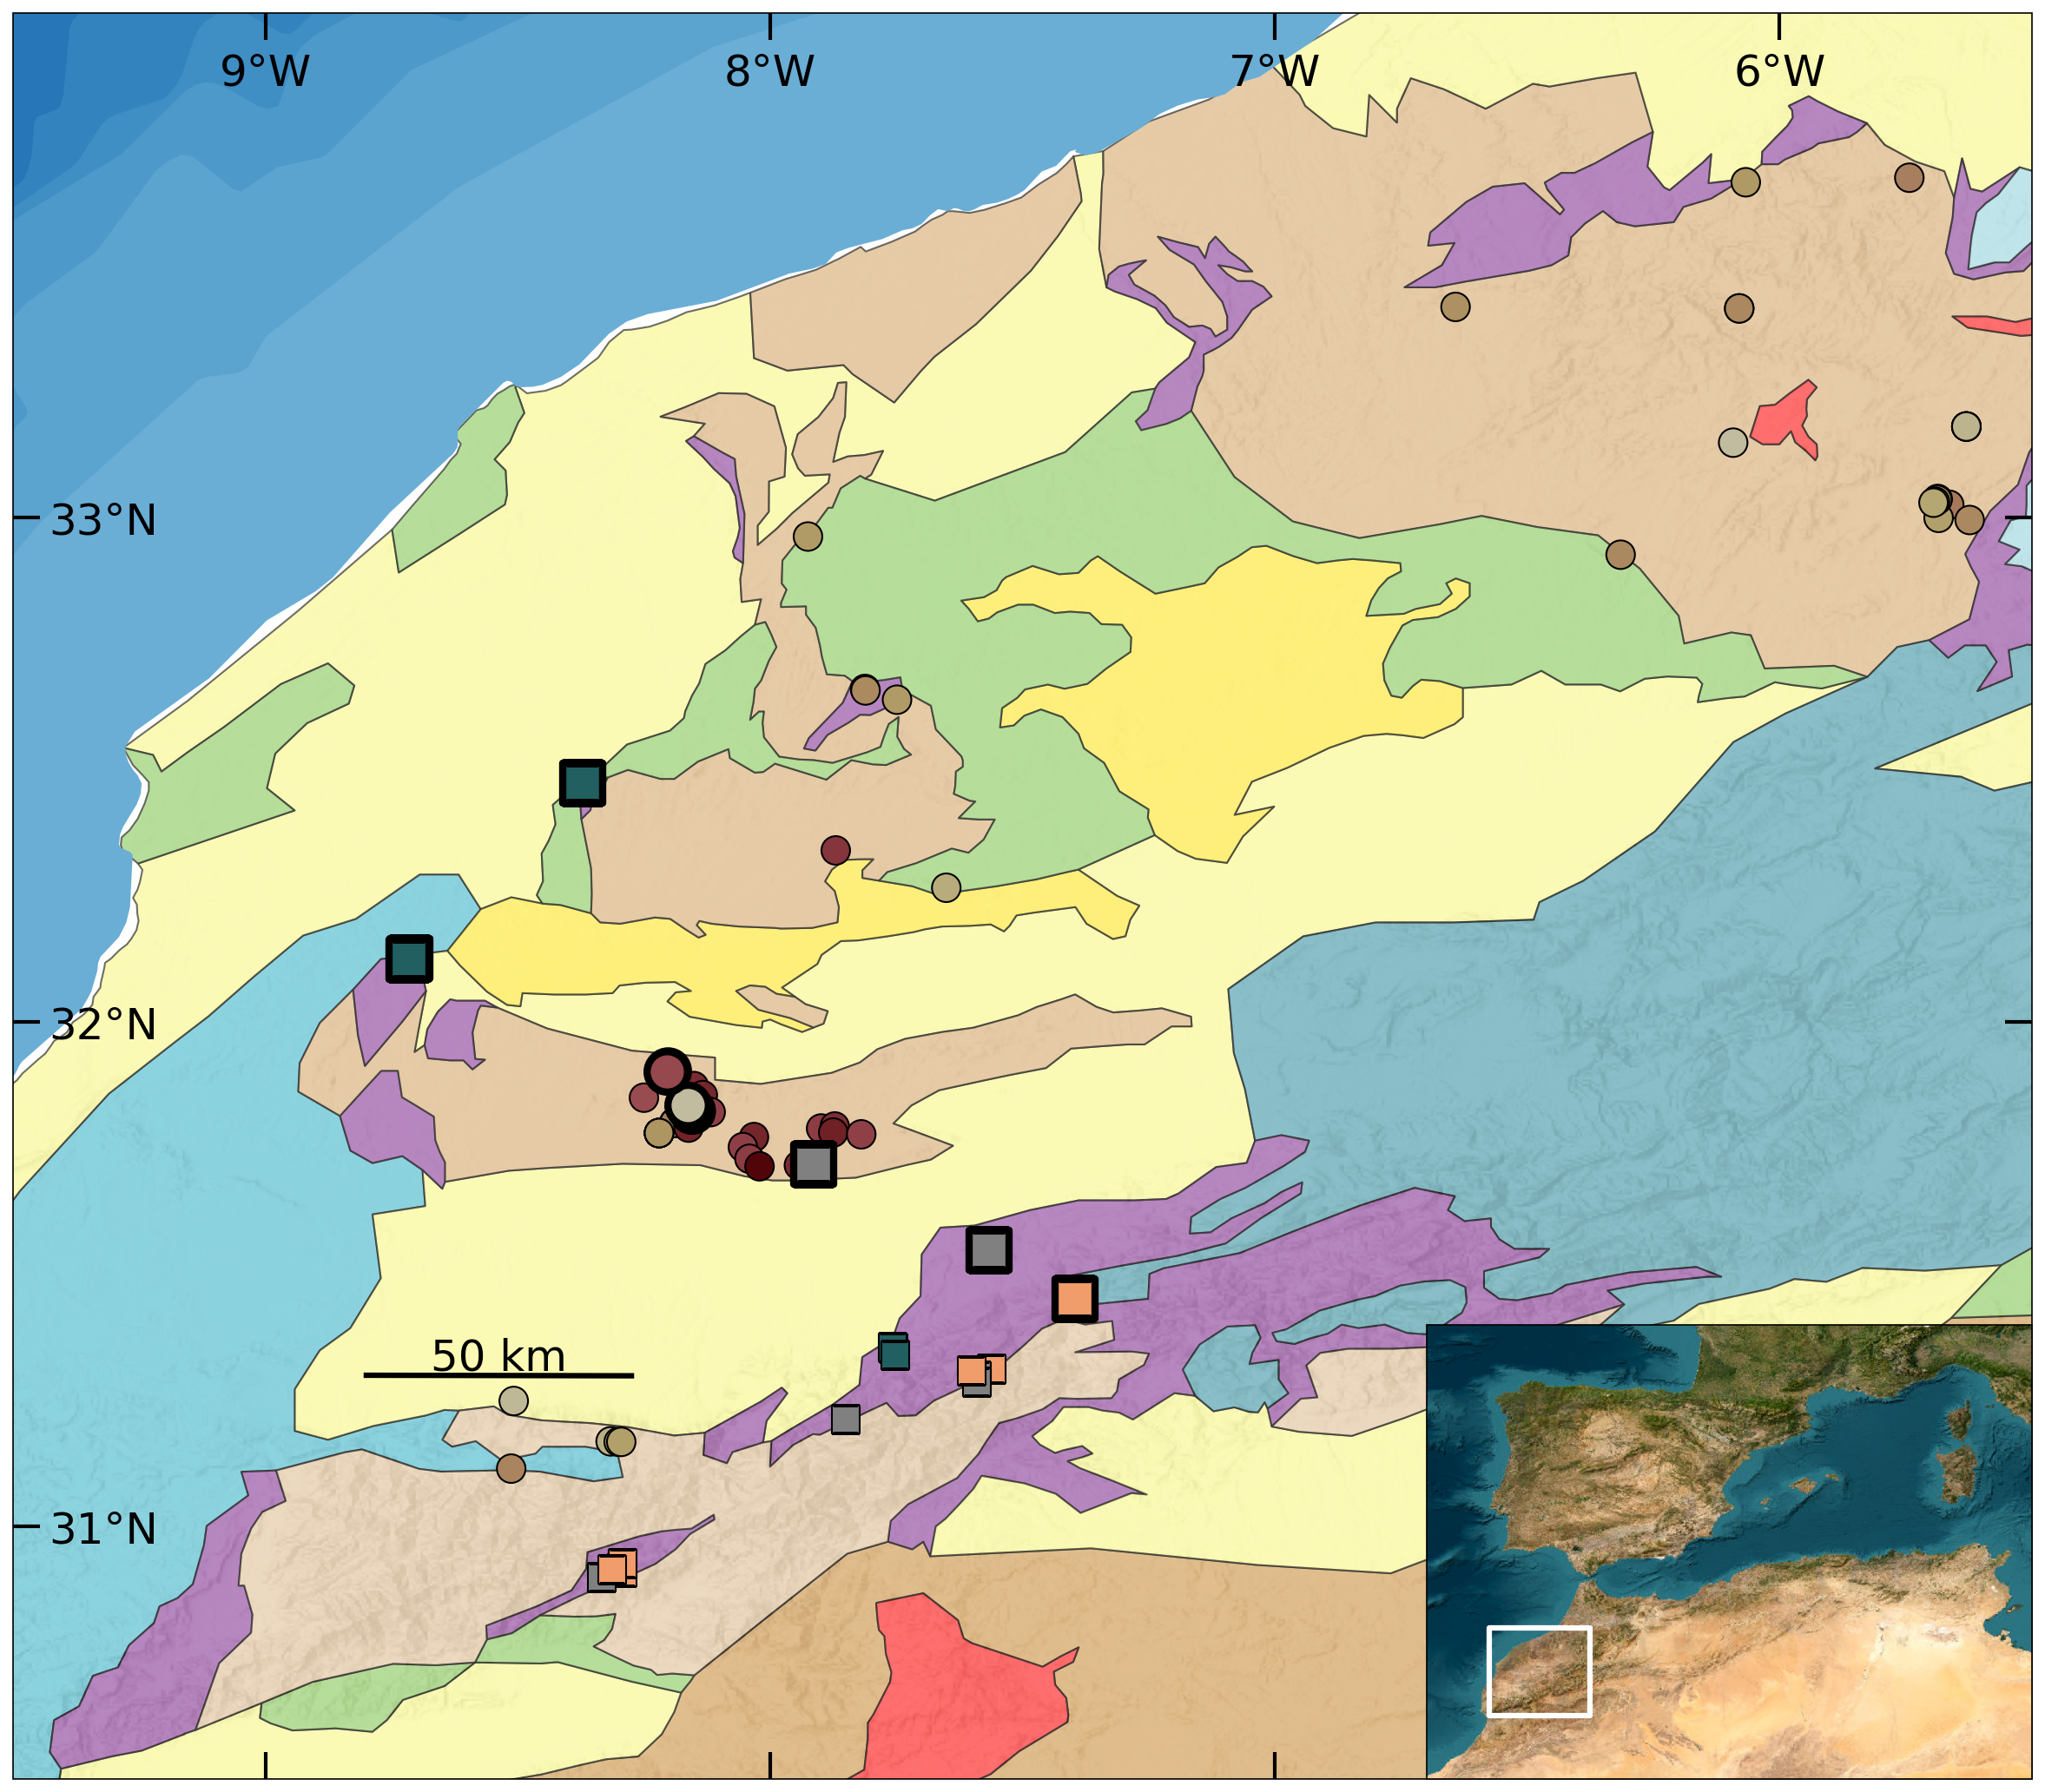

In [96]:
fs = 24  # Base font size for poster
cmap = cmc.bilbao_r
norm = plt.Normalize(vmin=240, vmax=360)

fig, ax = plt.subplots(1, figsize=(20,20), dpi=150,
                         subplot_kw={'projection':ccrs.PlateCarree()})
ax.set_extent([-9.5,-5.5,30.5,34])
ax.add_image(hillshade,9,alpha=0.2, zorder=0.5)
tect_map.plot(ax=ax,color=tect_map['unit_color'],alpha=0.7, zorder=0,
                edgecolor='black', linewidth=1)
maps.bath(ax=ax) 

ax.set_xticks(np.arange(-9, -5, 1))
ax.set_yticks(np.arange(31, 34, 1))
ax.xaxis.set_major_formatter(LongitudeFormatter())
ax.yaxis.set_major_formatter(LatitudeFormatter())

ax.tick_params(direction='in', length=15, width=2, labelsize=fs, top=True, right=True,
               labeltop=True, labelbottom=False, labelright=False)
ax.tick_params(axis='x', pad=-45)
ax.tick_params(axis='y', pad=-80)


maps.scalebar(length=50e3,color='black',ax=ax,slon=-8.8,slat=31.3)
ax.texts[-1].set_fontsize(fs)

for smp in smps_ptr:
    new = smp.source=='Vasey'
    ax.scatter(smp.latlon[1],smp.latlon[0],color=smp.color,marker='s',
               edgecolor='black',linewidth=4 if new else 1,s=500 if new else 250,zorder=4)
    #if new:
    #    ax.annotate(mr24_dict.get(smp.name,smp.name),(smp.latlon[1],smp.latlon[0]),
                    #xytext=(12,8),textcoords='offset points',fontsize=fs-4,fontweight='bold')

for new, group in data_ig.groupby('New'):
    sc = ax.scatter(group['Longitude (DD)'],group['Latitude (DD)'],c=group['Age (Ma)'],
                    cmap=cmap,norm=norm,marker='o',s=500 if new else 250,
                    edgecolor='black',linewidth=4 if new else 1,zorder=5 if new else 3)
#for smp in smps_ig:
    #ax.annotate(new_names_dict[smp.name],(smp.latlon[1],smp.latlon[0]),
    #            xytext=(12,-20),textcoords='offset points',fontsize=fs-4,fontweight='bold')

# Igneous age colorbar
#cax = ax.inset_axes([0.04,0.93,0.3,0.015])
#cbar = fig.colorbar(sc,cax=cax,orientation='horizontal')
#cbar.set_label('Igneous zircon U-Pb age (Ma)',fontsize=fs)
#cbar.ax.tick_params(labelsize=fs-4)

# Western Mediterranean inset
inset = ax.inset_axes([0.7,0.0,0.3,0.3], projection=ccrs.PlateCarree())
inset.set_anchor('SE')
inset.set_extent([-12,12,28,46], crs=ccrs.PlateCarree())
inset.add_image(sattelite,5)
maps.bb_auto(ax,ax=inset,facecolor='none',edgecolor='white',linewidth=3)

fig.savefig('agu_map.pdf')